# Machine Learning Assignment – 2
## Classification Models and Performance Evaluation

**Programme:** M.Tech (AIML)  
**Subject:** Machine Learning  

**BITS ID:** 2026AJ05421

### Objective
The objective of this assignment is to implement five classification algorithms on the same dataset and compare their performance using Accuracy, AUC, Precision, Recall, F1-score and Matthews Correlation Coefficient (MCC).

The models used are:
1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbour (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

*Run the notebook from top to bottom. The metric values and observations will be generated from the actual execution; they should not be entered manually.*

## Step 1: Import the required libraries

The following libraries are used for data handling, visualization, model building and evaluation.

In [3]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
import warnings
import joblib
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Dataset selection and loading
The Breast Cancer Wisconsin Diagnostic dataset is loaded from Scikit-learn. It contains 569 observations and 30 numerical input features. 
The target variable has two classes: malignant and benign.*

The dataset is suitable for a binary classification task and meets the assignments minimum feature and instance requirements.

In [6]:
dataset = load_breast_cancer()

X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="target")

# Keep a readable target label for understanding the data.
target_names = {0: "malignant", 1: "benign"}

print("Dataset shape:", X.shape)
print("Number of input features:", X.shape[1])
print("Number of instances:", X.shape[0])
print("\\nTarget class names:", dataset.target_names)
print("\\nClass distribution:")
print(y.map(target_names).value_counts())

Dataset shape: (569, 30)
Number of input features: 30
Number of instances: 569
\nTarget class names: ['malignant' 'benign']
\nClass distribution:
target
benign       357
malignant    212
Name: count, dtype: int64


## Step 3: Exploratory data analysis

First, the dataset is inspected to understand its structure, data types, missing values and class distribution.

In [8]:
display(X.head())
print("Dataset information:")
X.info()

print("\\nMissing values:", X.isnull().sum().sum())
print("\\nDescriptive statistics:")
display(X.describe().T)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


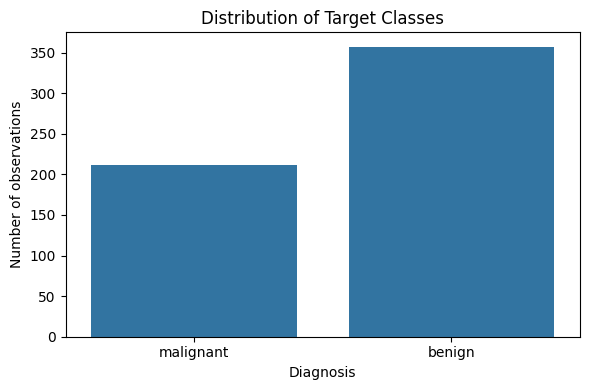

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y.map(target_names))
plt.title("Distribution of Target Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

## Step 4: Split the dataset into training and testing sets

The dataset is divided into 80% training data and 20% testing data. Stratification is used to preserve the class distribution in both sets. The test data is kept separate and is not used to train the models.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (455, 30)
Testing feature shape: (114, 30)
Training target shape: (455,)
Testing target shape: (114,)


## Step 5: Build the five classification models

All five models use the same training and testing split. Standardisation is included in the pipelines for Logistic Regression, KNN, Gaussian Naive Bayes and SVM. The Decision Tree model is used without feature scaling.

Using pipelines ensures that scaling is fitted only on the training data and then applied to the test data.

In [13]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ]),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(probability=True, random_state=RANDOM_STATE))
    ])
}

print("Five classification models are ready.")

Five classification models are ready.


## Step 6: Train the models and evaluate their performance

Each model is trained using the training dataset. Predictions are made on the unseen test dataset.

The following evaluation metrics are calculated:
- **Accuracy:** Overall proportion of correct predictions.
- **AUC:** Area under the ROC curve.
- **Precision:** Proportion of positive predictions that are correct.
- **Recall:** Proportion of actual positive cases correctly identified.
- **F1-score:** Harmonic mean of precision and recall.
- **MCC:** Matthews Correlation Coefficient, which considers all four confusion-matrix outcomes.

The positive class is the dataset's class `1` (benign). AUC is calculated using predicted probabilities.

In [15]:
results = []
trained_models = {}
predictions = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_probability = model.predict_proba(X_test)[:, 1]

    trained_models[model_name] = model
    predictions[model_name] = y_pred

    results.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_probability),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

results_df = pd.DataFrame(results).set_index("ML Model Name")
results_df = results_df.sort_values(by="F1 Score", ascending=False)

print("Model evaluation completed.")
display(results_df.round(4))

Model evaluation completed.


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
ML Model Name,,,,,,
Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623
KNN,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
Naive Bayes,0.9298,0.9868,0.9444,0.9444,0.9444,0.8492
Decision Tree,0.9123,0.9157,0.9559,0.9028,0.9286,0.8174


## Step 7: Visual comparison of evaluation metrics

The following bar charts compare the performance of all five models across the six evaluation metrics.

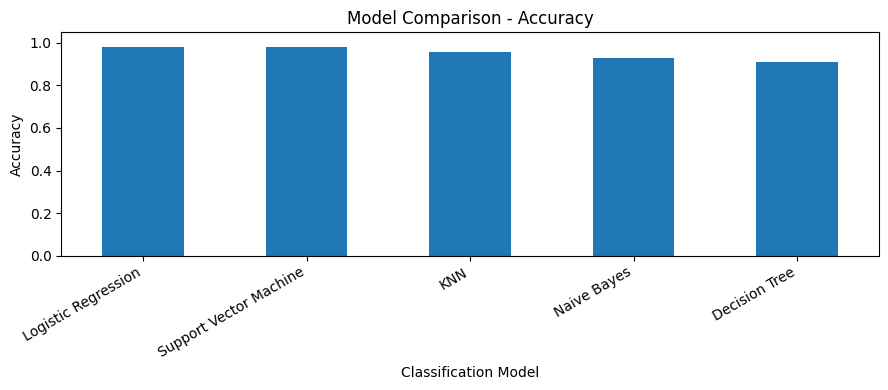

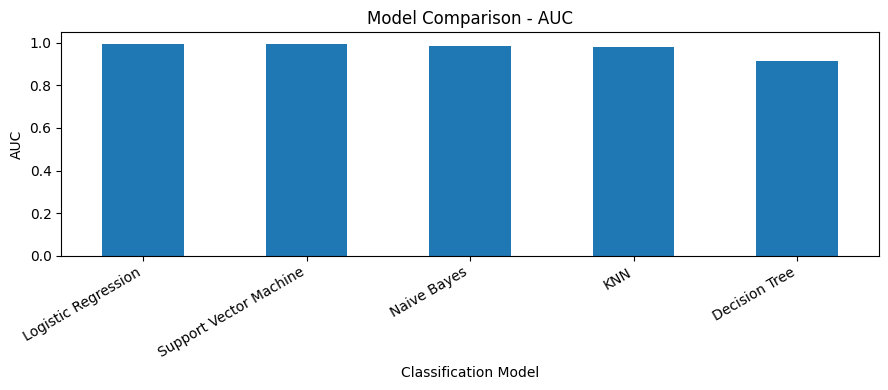

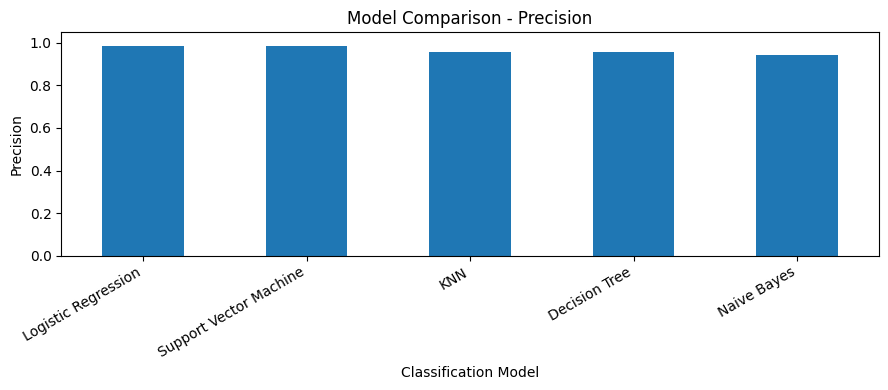

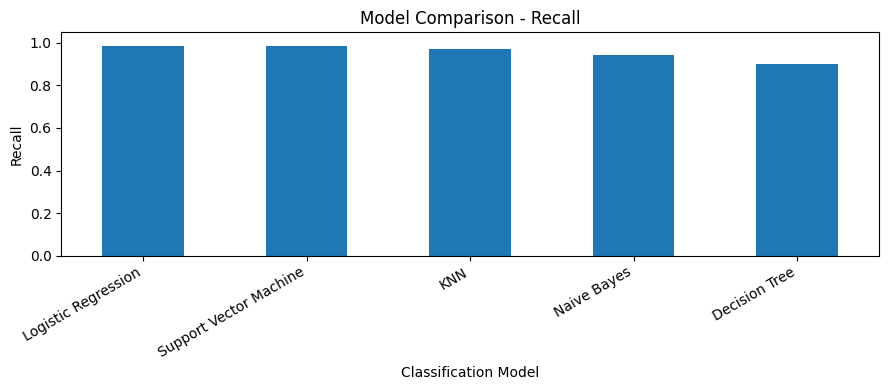

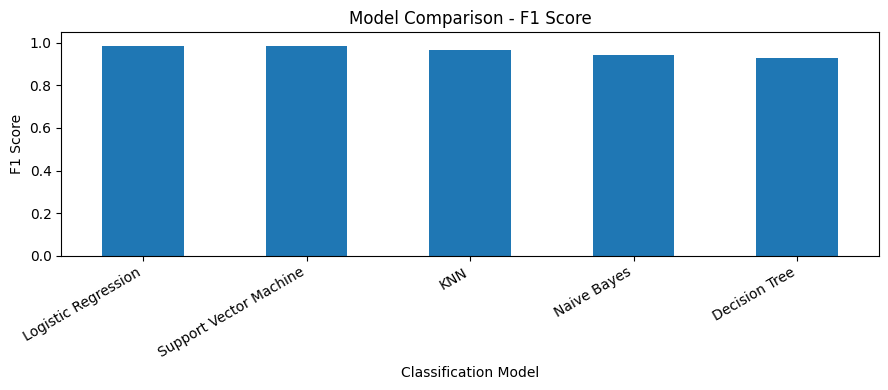

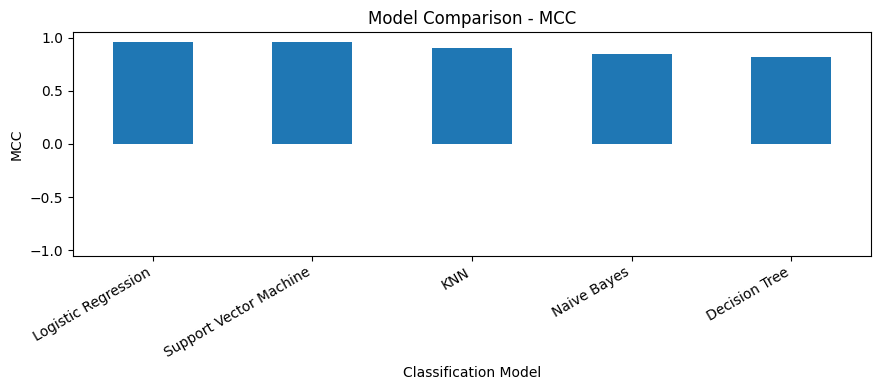

In [17]:
metrics = ["Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC"]

for metric in metrics:
    plt.figure(figsize=(9, 4))
    results_df[metric].sort_values(ascending=False).plot(
        kind="bar", title=f"Model Comparison - {metric}"
    )
    plt.ylabel(metric)
    plt.xlabel("Classification Model")
    plt.xticks(rotation=30, ha="right")
    plt.ylim(-1.05 if metric == "MCC" else 0, 1.05)
    plt.tight_layout()
    plt.show()

## Step 8: Confusion matrix and classification report

A confusion matrix and classification report are generated for each model. These provide more detailed information about correct and incorrect classifications.

\n=================================================================
Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



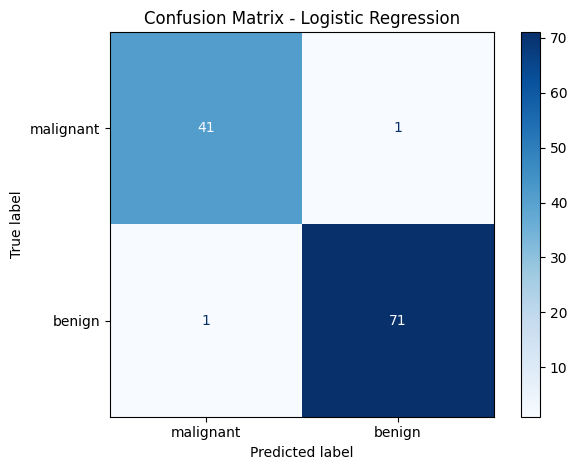

\n=================================================================
Decision Tree
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



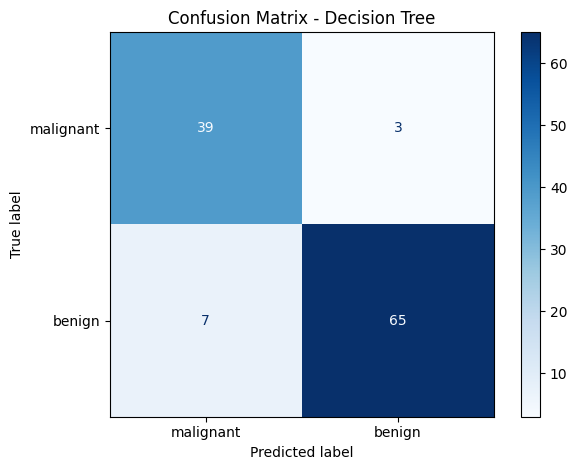

\n=================================================================
KNN
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



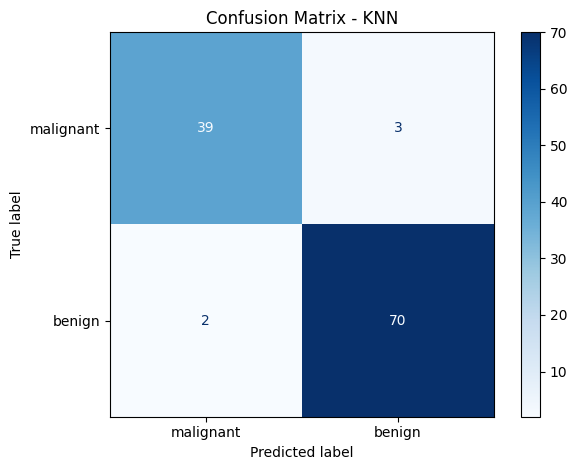

\n=================================================================
Naive Bayes
              precision    recall  f1-score   support

   malignant       0.90      0.90      0.90        42
      benign       0.94      0.94      0.94        72

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



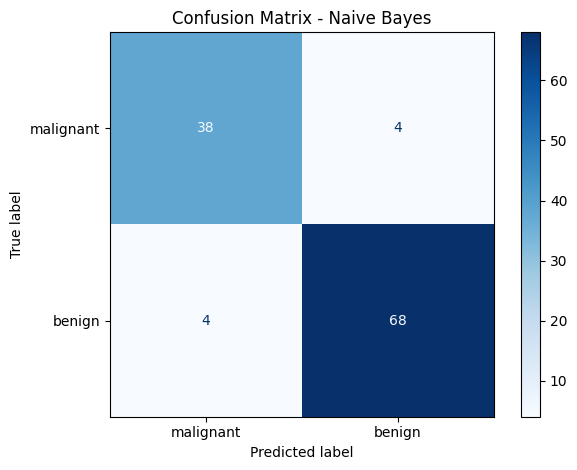

\n=================================================================
Support Vector Machine
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



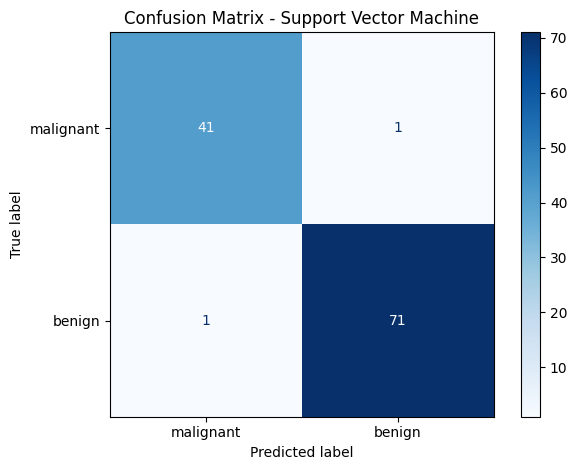

In [19]:
for model_name, y_pred in predictions.items():
    print("\\n" + "=" * 65)
    print(model_name)
    print("=" * 65)
    print(classification_report(
        y_test, y_pred,
        target_names=dataset.target_names,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=dataset.target_names
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

## Step 9: Model-wise observations and identification of the best model

The following cell generates observations from the actual metric values. These observations can be used in the assignment's README comparison section. The overall winner below is selected using F1-score; the complete metric table should also be considered when discussing model performance.

In [21]:
print("MODEL-WISE PERFORMANCE OBSERVATIONS")
print("-" * 65)

for model_name, row in results_df.iterrows():
    print(f"\\n{model_name}:")
    print(
        f"Accuracy = {row['Accuracy']:.4f}, "
        f"AUC = {row['AUC']:.4f}, "
        f"Precision = {row['Precision']:.4f}, "
        f"Recall = {row['Recall']:.4f}, "
        f"F1 = {row['F1 Score']:.4f}, "
        f"MCC = {row['MCC']:.4f}."
    )
    print(
        f"The model correctly classifies {row['Accuracy'] * 100:.2f}% "
        f"of the test observations. Its F1-score is {row['F1 Score']:.4f} "
        f"and MCC is {row['MCC']:.4f}."
    )

winner = results_df["F1 Score"].idxmax()
print("\\nOVERALL WINNER (based on highest F1-score):", winner)
print("Winner's metrics:")
display(results_df.loc[[winner]].round(4))

MODEL-WISE PERFORMANCE OBSERVATIONS
-----------------------------------------------------------------
\nLogistic Regression:
Accuracy = 0.9825, AUC = 0.9954, Precision = 0.9861, Recall = 0.9861, F1 = 0.9861, MCC = 0.9623.
The model correctly classifies 98.25% of the test observations. Its F1-score is 0.9861 and MCC is 0.9623.
\nSupport Vector Machine:
Accuracy = 0.9825, AUC = 0.9950, Precision = 0.9861, Recall = 0.9861, F1 = 0.9861, MCC = 0.9623.
The model correctly classifies 98.25% of the test observations. Its F1-score is 0.9861 and MCC is 0.9623.
\nKNN:
Accuracy = 0.9561, AUC = 0.9788, Precision = 0.9589, Recall = 0.9722, F1 = 0.9655, MCC = 0.9054.
The model correctly classifies 95.61% of the test observations. Its F1-score is 0.9655 and MCC is 0.9054.
\nNaive Bayes:
Accuracy = 0.9298, AUC = 0.9868, Precision = 0.9444, Recall = 0.9444, F1 = 0.9444, MCC = 0.8492.
The model correctly classifies 92.98% of the test observations. Its F1-score is 0.9444 and MCC is 0.8492.
\nDecision Tree

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
ML Model Name,,,,,,
Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623


## Step 10: Save the trained models and test dataset

The trained pipelines are saved in the `model` folder. The test CSV contains all 30 input features and the target column, as required for the Streamlit application. The models are saved after training and are not retrained on the uploaded test CSV.

In [23]:
os.makedirs("model", exist_ok=True)

model_file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "support_vector_machine.joblib"
}

for model_name, model in trained_models.items():
    file_path = os.path.join("model", model_file_names[model_name])
    joblib.dump(model, file_path)
    print("Saved:", file_path)

test_data = X_test.copy()
test_data["target"] = y_test.values
test_data.to_csv("test_data.csv", index=False)

results_df.to_csv("model_comparison.csv")

print("\\nTest data saved as test_data.csv")
print("Model comparison saved as model_comparison.csv")

Saved: model/logistic_regression.joblib
Saved: model/decision_tree.joblib
Saved: model/knn.joblib
Saved: model/naive_bayes.joblib
Saved: model/support_vector_machine.joblib
\nTest data saved as test_data.csv
Model comparison saved as model_comparison.csv


## Step 11: Final conclusion

The five classification algorithms were implemented and evaluated on the same Breast Cancer Wisconsin Diagnostic dataset using a common train-test split.

The comparison table contains Accuracy, AUC, Precision, Recall, F1-score and MCC for every model. The best-performing model according to the selected F1-score criterion is displayed in Step 9.

**Conclusion:** Review the generated metric table and confusion matrices before writing the final conclusion. In particular, because this is a medical diagnostic dataset, recall and false-negative classifications should also be considered rather than selecting a model based only on accuracy.

### Files generated
- `model/` – saved trained classification pipelines.
- `test_data.csv` – held-out test data with the target column.
- `model_comparison.csv` – comparison of all model metrics.

These files can be included in the GitHub repository for the next part of the assignment: Streamlit application development and deployment.